# H13. 모터 전력의 주파수 대역 에너지가 펌프 누설에 따라 다른가

| 항목 | 내용 |
|---|---|
| 질문 | 모터 전력 신호를 떨림의 빠르기(주파수)로 나눠 보면 펌프 누설을 알 수 있을까? |
| 귀무가설 H0 | 모든 주파수 대역에서 에너지 분포는 펌프 누설과 관계없이 같다 |
| 대립가설 H1 | 적어도 한 대역에서 다르다 |
| 검정 | 대역 6개 Kruskal-Wallis (Holm), 효과 크기 ε², EPS1 평균과 비교 |
| 출처 (EDA) | F16 Welch PSD |
| 데이터 | 원본 EPS1.txt (100 Hz) → Welch PSD → 대역별 에너지(로그) |
| 왜 중요한가 | 주파수 특징(특징 v2)이 실제로 쓸모 있는지 |

**진행 순서:** 1 EDA 시각화 → 2 기술통계 → 3 가정 확인 → 4 정상성 확인 → 5 가설검정(p-값) → 6 사후검정·효과 크기 → 7 블록 평균 재확인 → 8 최종 판정 → 9 해석과 결정

유의수준은 **α = 0.05**로 미리 정했습니다. 표본이 2,205개로 커서 작은 차이도 p < 0.05가 되므로, **결론은 효과 크기와 함께** 내립니다.

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 1. EDA 시각화

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


... (2 outputs left out)

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


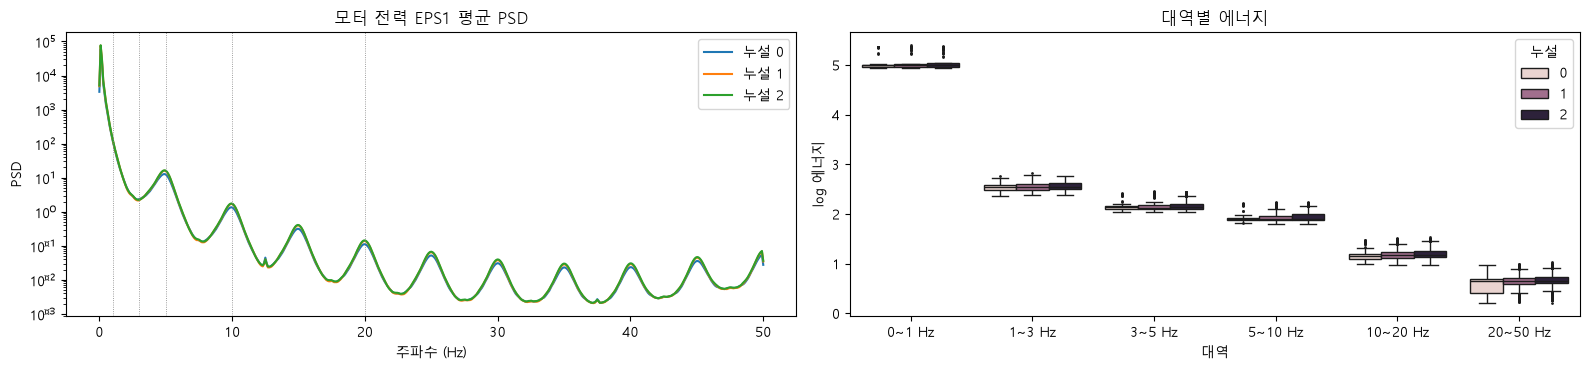

In [2]:
from scipy.signal import welch
eps = raw("EPS1"); fr, pxx = welch(eps, fs=100, nperseg=1024, axis=1)
BANDS = [(0, 1), (1, 3), (3, 5), (5, 10), (10, 20), (20, 50)]; BN = [f"{a}~{b} Hz" for a, b in BANDS]
E = pd.DataFrame({nm: np.log10(pxx[:, (fr >= a) & (fr < b)].sum(axis=1) + 1e-12) for nm, (a, b) in zip(BN, BANDS)})
c = "pump_leak"
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
for v in sorted(cyc[c].unique()): axes[0].semilogy(fr, pxx[(cyc[c] == v).values].mean(0), label=f"누설 {v}")
for a, _ in BANDS[1:]: axes[0].axvline(a, color="gray", ls=":", lw=0.6)
axes[0].set_xlabel("주파수 (Hz)"); axes[0].set_ylabel("PSD"); axes[0].legend(); axes[0].set_title("모터 전력 EPS1 평균 PSD")
d = E.assign(누설=cyc[c].values).melt(id_vars="누설", var_name="대역", value_name="log 에너지")
sns.boxplot(data=d, x="대역", y="log 에너지", hue="누설", ax=axes[1], fliersize=1); axes[1].set_title("대역별 에너지")
plt.tight_layout(); plt.show()

**EDA로 본 것:** 평균 PSD 곡선은 상태별로 조금 달라 보이지만, 사이클별 분포(박스)는 많이 겹칩니다.

## 2. 기술통계

In [3]:
display(E.groupby(cyc[c].values).mean().round(3))

,0~1 Hz,1~3 Hz,3~5 Hz,5~10 Hz,10~20 Hz,20~50 Hz
0,4.992,2.535,2.131,1.901,1.149,0.581
1,5.062,2.551,2.176,1.953,1.198,0.628
2,5.072,2.561,2.185,1.963,1.209,0.643


## 3. 가정 확인 (대표 대역 10~20 Hz)

In [4]:
cyc["EPS1_band_10_20"] = E["10~20 Hz"].values
tab, lev = assumption_table(cyc["EPS1_band_10_20"], cyc[c]); display(tab.round(3)); print(f"Levene p = {lev['p']:.2e} → Kruskal-Wallis 사용")

,그룹,n,왜도,K2,정규성_p,정규분포
0,0,1221,0.396,113.651,0.0,아니오
1,1,492,0.839,47.261,0.0,아니오
2,2,492,0.711,47.248,0.0,아니오


Levene p = 7.77e-50 → Kruskal-Wallis 사용


## 4. 정상성 확인

사이클 순서대로 본 이 특징이 **정상(평균·분산이 시간에 따라 일정)**인지 확인합니다. ADF(H0: 비정상)와 KPSS(H0: 정상)는 질문이 반대라서 함께 봅니다.

- 비정상이거나 자기상관이 크면 "관측값이 서로 독립"이라는 검정의 가정이 약해집니다. 그래서 7단계에서 **50사이클 블록 평균으로 다시 검정**합니다.
- KPSS p가 0.01이나 0.10으로 나오면 경계값입니다. 각각 "0.01 이하", "0.10 이상"으로 읽습니다.


,특징,계열,ADF_p,KPSS_p,판정
0,EPS1_band_10_20,원값,0.0072,0.010,추세·구조변화(둘 다 기각)
1,EPS1_band_10_20,1차 차분,0.0000,0.100,정상
2,EPS1_mean,원값,0.0006,0.010,추세·구조변화(둘 다 기각)
3,EPS1_mean,1차 차분,0.0000,0.100,정상


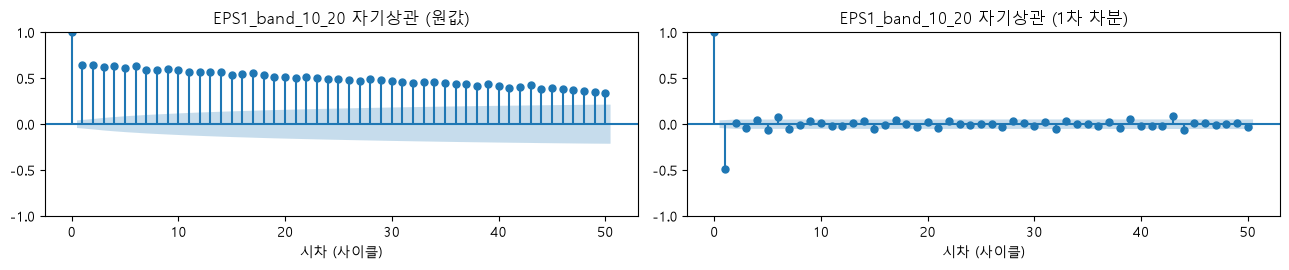

In [5]:
st = stationarity(cyc, ['EPS1_band_10_20', 'EPS1_mean'])
display(st.style.format({"ADF_p": "{:.4f}", "KPSS_p": "{:.3f}"}))
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
acf_plot(cyc['EPS1_band_10_20'], "EPS1_band_10_20 자기상관 (원값)", ax=axes[0])
acf_plot(cyc['EPS1_band_10_20'].diff(), "EPS1_band_10_20 자기상관 (1차 차분)", ax=axes[1])
plt.tight_layout(); plt.show()

## 5. 가설검정 (p-값) — 대역 6개

In [6]:
res = pd.DataFrame([dict(대역=nm, **kruskal_test(E[nm], cyc[c])) for nm in BN]); res["p_holm"] = holm(res["p"]); res["효과"] = res["eps2"].map(size_label)
base = kruskal_test(cyc["EPS1_mean"], cyc[c])
display(res.style.format({"H": "{:.1f}", "p": "{:.2e}", "p_holm": "{:.2e}", "eps2": "{:.4f}"}))
print(f"비교 — EPS1 단순 평균: H = {base['H']:.1f}, p = {base['p']:.2e}, ε² = {base['eps2']:.3f} ({size_label(base['eps2'])})")

,대역,H,df,p,eps2,n,p_holm,효과
0,0~1 Hz,30.6,2,2.31e-07,0.0139,2205,9.23e-07,작음
1,1~3 Hz,20.3,2,3.86e-05,0.0092,2205,7.71e-05,매우 작음
2,3~5 Hz,18.2,2,1.11e-04,0.0083,2205,1.11e-04,매우 작음
3,5~10 Hz,23.1,2,9.43e-06,0.0105,2205,2.83e-05,작음
4,10~20 Hz,41.9,2,8.12e-10,0.0190,2205,4.87e-09,작음
5,20~50 Hz,36.9,2,9.61e-09,0.0168,2205,4.81e-08,작음


비교 — EPS1 단순 평균: H = 556.9, p = 1.20e-121, ε² = 0.253 (큼)


## 6. 효과 크기 비교

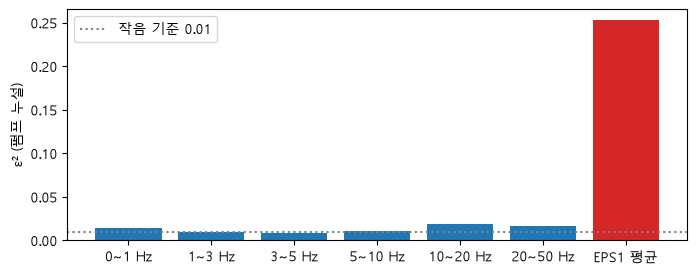

,쌍,z,p,p_holm,유의
0,0 vs 1,-4.24,2.20e-05,4.40e-05,예
1,0 vs 2,-5.90,3.69e-09,1.11e-08,예
2,1 vs 2,-1.39,1.66e-01,1.66e-01,아니오


In [7]:
fig, ax = plt.subplots(figsize=(8, 3)); ax.bar(BN + ["EPS1 평균"], list(res.eps2) + [base["eps2"]], color=["C0"] * 6 + ["C3"])
ax.set_ylabel("ε² (펌프 누설)"); ax.axhline(0.01, color="gray", ls=":", label="작음 기준 0.01"); ax.legend(); plt.show()
best = res.eps2.idxmax(); display(dunn_test(E[BN[best]], cyc[c]).style.format({"z": "{:.2f}", "p": "{:.2e}", "p_holm": "{:.2e}"}))

## 7. 블록 평균으로 재확인 (가장 큰 대역)

In [8]:
cyc["EPS1_best_band"] = E[BN[best]].values; b = block_means(cyc, "EPS1_best_band", c); rb = kruskal_test(b["EPS1_best_band"], b[c])
print(f"{BN[best]}: 블록 {len(b)}개, H = {rb['H']:.1f}, p = {rb['p']:.3g}, ε² = {rb['eps2']:.3f}")

10~20 Hz: 블록 80개, H = 1.2, p = 0.547, ε² = 0.015


## 8. 최종 판정

**p < 0.05여도 효과 크기가 0.01~0.02 수준이면 실질적 차이가 거의 없다고 판정**합니다.

In [9]:
final = pd.DataFrame([dict(가설="H13", 검정="Kruskal-Wallis (6대역, Holm)", 유의대역=f"{(res.p_holm < ALPHA).sum()}/6", p_holm_최대=res.p_holm.max(),
    효과크기=f"ε² = {res.eps2.min():.3f}~{res.eps2.max():.3f} (EPS1 평균 {base['eps2']:.2f})", 블록_p=rb["p"],
    판정="H0 기각이나 효과 매우 작음" if (res.p_holm < ALPHA).any() and res.eps2.max() < 0.06 else ("H0 기각" if (res.p_holm < ALPHA).any() else "H0 유지"))])
display(final)
save_result("H13", title="EPS1 주파수 대역 × 펌프 누설", test="Kruskal-Wallis (Holm)", stat=f"유의 대역 {(res.p_holm < ALPHA).sum()}/6",
            p=float(res.p_holm.max()), effect=final.효과크기[0], verdict=final.판정[0])

,가설,검정,유의대역,p_holm_최대,효과크기,블록_p,판정
0,H13,"Kruskal-Wallis (6대역, Holm)",6/6,0.000111,ε² = 0.008~0.019 (EPS1 평균 0.25),0.546694,H0 기각이나 효과 매우 작음


저장: results/H13.json


## 9. 해석과 결정

- 통계적으로는 모든 대역이 유의하지만, 효과 크기가 0.01~0.02로 매우 작습니다. 단순 평균(EPS1_mean)의 효과가 훨씬 큽니다(≈ 0.25).
- **"p < 0.05인데도 효과 크기로 실질적 차이 없음을 판정"하는 사례**입니다. 발표에서 효과 크기가 왜 중요한지 보여 주기 좋습니다.
- **결정:** 특징 v2에서 주파수 특징은 일괄로 넣지 말고, **센서·부품별로 효과가 있는 것만 골라** 씁니다(4.1.1).